# Assignment 1 – Exploratory Data Analysis (EDA)

**Student Name:** Sangeetha

**Project Name:** Abnormal Patterns in Continuous Patient Monitoring

## Objective
Explore, clean, analyze and visualize a real-world dataset using Python.
Here the data are five continuously monitored vital signs of **intensive-care patients**: **heart rate, SpO₂, mean blood pressure, body temperature and respiratory rate**.

## 1. Dataset Information and Source

**Dataset Name:** eICU Collaborative Research Database – Demo (v2.0.1)

**Source:** MIT Laboratory for Computational Physiology and the Philips eICU Research Institute, distributed through PhysioNet. Reference: Pollard et al., *Scientific Data*, 2018.

**Source URL:** https://physionet.org/content/eicu-crd-demo/2.0.1/  ·  https://eicu-crd.mit.edu

**License / access:** Open access (Open Data Commons Open Database License), no login needed. It is a public subset of the full eICU database, which covers over 200,000 ICU admissions across hospitals in the United States (2014–2015).

**Description:** The `vitalPeriodic` table holds bedside-monitor data of ICU patients, stored as **5-minute median values**. The `patient` table adds demographics, ICU unit type and hospital outcome.
This project uses five columns:

| Short name | eICU column | Meaning | Unit |
|---|---|---|---|
| HR | `heartrate` | Heart rate | beats/min |
| SpO2 | `sao2` | Oxygen saturation | % |
| MAP | `systemicmean` | Invasive mean arterial (blood) pressure | mmHg |
| Temp | `temperature` | Body temperature | °C |
| RR | `respiration` | Respiratory rate | breaths/min |

It is relevant because ICU monitoring data mix **genuine physiological change, short harmless deviations and sensor artifacts**, so careful cleaning and exploration is needed before any pattern-finding or modelling.

*Compared with surgical (operating-theatre) data: patients are sicker, recordings last days instead of hours, and values are 5-minute medians, so very short spikes are already smoothed out.*

## 2. Import Libraries

In [1]:
import io, os, warnings
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Dataset

The two files are downloaded directly from PhysioNet (about 20 MB, takes under a minute):

* `vitalPeriodic.csv.gz` – the vital signs (one row per 5-minute observation)
* `patient.csv.gz` – one row per ICU stay (gender, age, unit type, hospital outcome)

We keep the **first 24 hours of each ICU stay** and choose **60 random stays that have all five vitals recorded** (fixed random seed, so results are reproducible). Invasive blood pressure and temperature are only recorded for some patients, which is why not every stay qualifies.
The data are placed on a regular 5-minute time grid per patient, so a missing reading shows up as a real gap.

In [2]:
VITALS = ["HR", "SpO2", "MAP", "Temp", "RR"]
COLS   = {"heartrate": "HR", "sao2": "SpO2", "systemicmean": "MAP", "temperature": "Temp", "respiration": "RR"}
UNITS  = {"HR": "beats/min", "SpO2": "%", "MAP": "mmHg", "Temp": "°C", "RR": "breaths/min"}
HOURS, N_STAYS, SEED = 24, 60, 42          # first 24 h of each stay; change N_STAYS to use more patients
INTERVAL = 300                             # seconds: the table stores 5-minute medians
BASE = "https://physionet.org/files/eicu-crd-demo/2.0.1/"

def fetch(name):
    """Download once; if the file already exists in the Colab session, use that copy."""
    if not os.path.exists(name):
        r = requests.get(BASE + name, headers={"User-Agent": "Mozilla/5.0"}, timeout=300)
        r.raise_for_status()
        with open(name, "wb") as f:
            f.write(r.content)
    return name

vit = pd.read_csv(fetch("vitalPeriodic.csv.gz"))
pat = pd.read_csv(fetch("patient.csv.gz"))
print("vitalPeriodic rows:", f"{len(vit):,}", "| ICU stays in file:", vit.patientunitstayid.nunique())

vit = vit[vit.observationoffset.between(0, HOURS * 60)]
vit = vit[["patientunitstayid", "observationoffset"] + list(COLS)].rename(columns=COLS)

# stays with enough readings of ALL five vitals (relax the requirement if too few stays qualify)
for min_n in (12, 6, 3):
    counts = vit.groupby("patientunitstayid")[VITALS].count()
    eligible = counts[(counts >= min_n).all(axis=1)].index
    if len(eligible) >= 20:
        break
print(f"Stays with >= {min_n} readings of every vital in the first {HOURS} h: {len(eligible)}")
chosen = sorted(np.random.default_rng(SEED).choice(eligible, size=min(N_STAYS, len(eligible)), replace=False))

frames = []
for sid in chosen:                                          # regular 5-minute grid per patient
    g = vit[vit.patientunitstayid == sid].copy()
    g["t"] = (g.observationoffset / 5).round().astype(int) * 5
    g = g.groupby("t")[VITALS].first()
    g = g.reindex(np.arange(0, g.index.max() + 5, 5))
    g.index.name = "t"
    g = g.reset_index()
    g.insert(0, "time_s", g.pop("t") * 60)
    g.insert(0, "caseid", int(sid))
    frames.append(g)
df = pd.concat(frames, ignore_index=True)

# patient information
pat = pat.rename(columns={"patientunitstayid": "caseid", "unittype": "unit_type", "hospitaldischargestatus": "outcome"})
pat["age"] = pd.to_numeric(pat["age"].astype(str).str.replace("> 89", "90", regex=False), errors="coerce")
keep = [c for c in ["caseid", "gender", "age", "unit_type", "outcome"] if c in pat.columns]
df = df.merge(pat[keep], on="caseid", how="left")
df["age_group"] = pd.cut(df["age"], [0, 49, 64, 79, 200], labels=["<50", "50-64", "65-79", "80+"]).astype(object)

df_raw = df.copy()                                          # untouched copy for before/after comparisons
print("Loaded:", len(chosen), "ICU stays")
print("Shape:", df.shape)

vitalPeriodic rows: 1,634,960 | ICU stays in file: 2375
Stays with >= 12 readings of every vital in the first 24 h: 61
Loaded: 60 ICU stays
Shape: (16592, 12)


> **If the download fails** (no internet, PhysioNet busy): open the PhysioNet page above, download `vitalPeriodic.csv.gz` and `patient.csv.gz`, drag both into Colab's *Files* panel (left side), and run the previous cell again. It automatically uses the local copies.

## 4. Initial Data Exploration

In [3]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nInfo:")
df.info()
print("\nStatistics:")
display(df.describe(include="all").T)

,caseid,time_s,HR,SpO2,MAP,Temp,RR,gender,age,unit_type,outcome,age_group
0,192233,0,NaN,NaN,NaN,NaN,NaN,Female,55.0,Med-Surg ICU,Alive,50-64
1,192233,300,86.0,95.0,96.0,NaN,13.0,Female,55.0,Med-Surg ICU,Alive,50-64
2,192233,600,83.0,93.0,96.0,NaN,13.0,Female,55.0,Med-Surg ICU,Alive,50-64
3,192233,900,88.0,93.0,98.0,NaN,14.0,Female,55.0,Med-Surg ICU,Alive,50-64
4,192233,1200,85.0,95.0,102.0,NaN,8.0,Female,55.0,Med-Surg ICU,Alive,50-64


,caseid,time_s,HR,SpO2,MAP,Temp,RR,gender,age,unit_type,outcome,age_group
16587,3352230,69300,101.0,99.0,106.0,38.6,14.0,Male,41.0,CTICU,Alive,<50
16588,3352230,69600,100.0,99.0,104.0,38.6,15.0,Male,41.0,CTICU,Alive,<50
16589,3352230,69900,103.0,99.0,105.0,38.6,17.0,Male,41.0,CTICU,Alive,<50
16590,3352230,70200,102.0,99.0,106.0,38.6,15.0,Male,41.0,CTICU,Alive,<50
16591,3352230,70500,103.0,99.0,103.0,38.6,17.0,Male,41.0,CTICU,Alive,<50


Shape: (16592, 12)

Columns:
['caseid', 'time_s', 'HR', 'SpO2', 'MAP', 'Temp', 'RR', 'gender', 'age', 'unit_type', 'outcome', 'age_group']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16592 entries, 0 to 16591
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   caseid     16592 non-null  int64  
 1   time_s     16592 non-null  int64  
 2   HR         16156 non-null  float64
 3   SpO2       15549 non-null  float64
 4   MAP        13584 non-null  float64
 5   Temp       12915 non-null  float64
 6   RR         15504 non-null  float64
 7   gender     16592 non-null  object 
 8   age        16592 non-null  float64
 9   unit_type  16592 non-null  object 
 10  outcome    16304 non-null  object 
 11  age_group  16592 non-null  object 
dtypes: float64(6), int64(2), object(4)
memory usage: 1.5+ MB

Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
caseid,16592.0,NaN,NaN,NaN,2246485.820938,913321.215867,192233.0,1558170.0,2686685.0,2867190.0,3352230.0
time_s,16592.0,NaN,NaN,NaN,42209.32377,24785.864388,0.0,20700.0,42000.0,63300.0,86400.0
HR,16156.0,NaN,NaN,NaN,83.70432,15.351135,20.0,75.0,83.0,92.0,167.0
SpO2,15549.0,NaN,NaN,NaN,97.234227,3.63259,6.0,96.0,98.0,100.0,100.0
MAP,13584.0,NaN,NaN,NaN,74.427856,14.86182,-2.0,65.0,73.0,82.0,343.0
Temp,12915.0,NaN,NaN,NaN,38.876268,10.653855,13.9,36.7,37.1,37.6,100.2
RR,15504.0,NaN,NaN,NaN,16.794053,6.942737,0.0,14.0,16.0,20.0,142.0
gender,16592,2,Male,11957,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,16592.0,NaN,NaN,NaN,66.97987,13.229331,22.0,58.0,68.0,77.0,90.0
unit_type,16592,6,Med-Surg ICU,10057,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data Quality – Missing Values

Missing values here are mostly **structural**: the patient had no arterial line or temperature probe for a while, the monitor was disconnected, or no value was recorded in that 5-minute slot. They are not random, so they need to be understood before they are treated.

In [4]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing)

,Missing Count,Missing Percentage
Temp,3677,22.16
MAP,3008,18.13
RR,1088,6.56
SpO2,1043,6.29
HR,436,2.63
outcome,288,1.74
caseid,0,0.00
time_s,0,0.00
gender,0,0.00
age,0,0.00


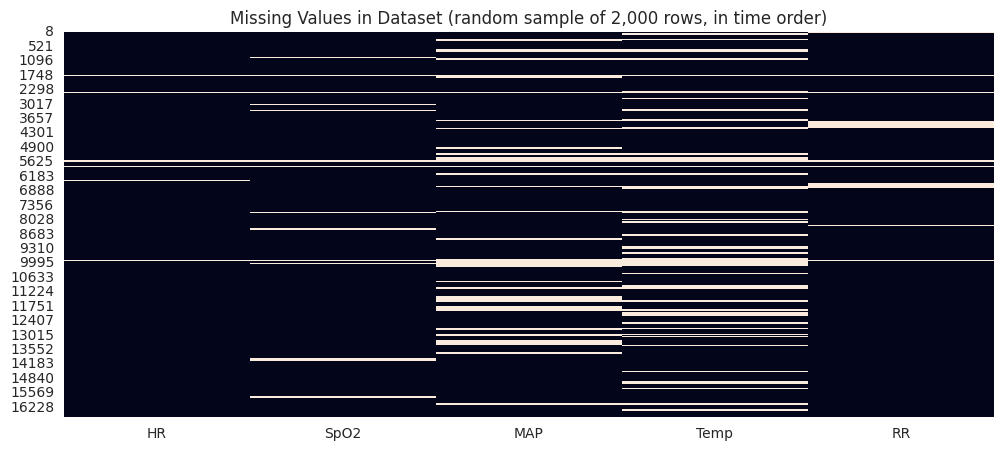

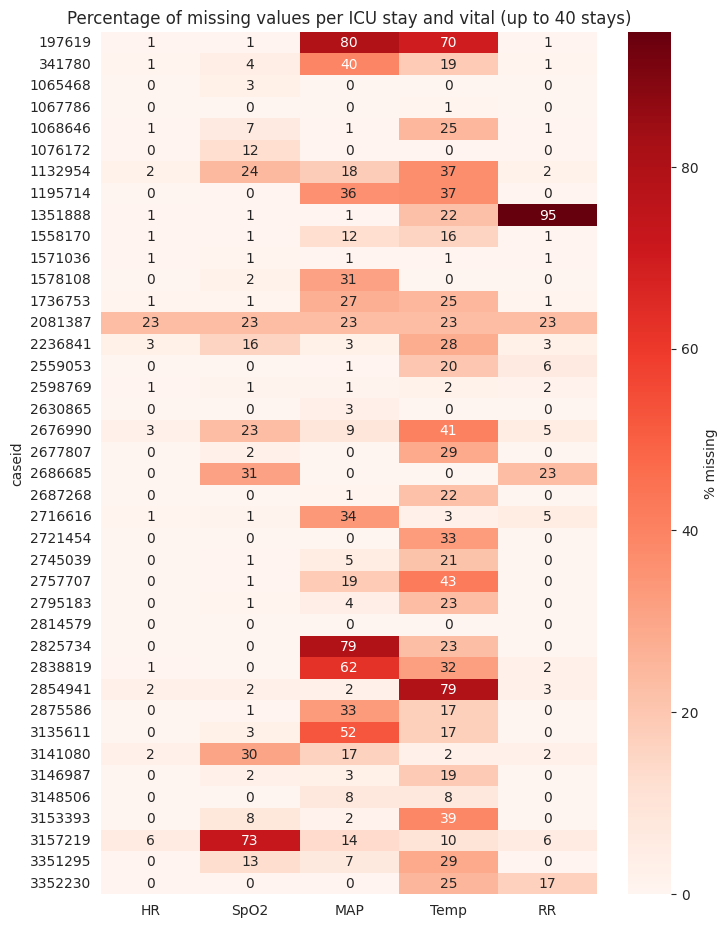

In [5]:
plt.figure(figsize=(12, 5))
sns.heatmap(df[VITALS].sample(min(2000, len(df)), random_state=0).sort_index().isnull(), cbar=False)
plt.title("Missing Values in Dataset (random sample of 2,000 rows, in time order)")
plt.show()

# Is missingness the same for every patient?
miss_case = df.groupby("caseid")[VITALS].apply(lambda g: g.isnull().mean() * 100)
miss_case = miss_case.sample(min(40, len(miss_case)), random_state=0).sort_index()   # at most 40 stays shown
plt.figure(figsize=(8, max(4, len(miss_case) * 0.28)))
sns.heatmap(miss_case, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("Percentage of missing values per ICU stay and vital (up to 40 stays)")
plt.show()

## 6. Duplicate, Data-Type and Inconsistent-Data Checks

* A row is only a *true* duplicate if the same case and the same timestamp appear twice.
* Identical vital values in different rows are **normal** (a stable heart rate repeats), so dropping rows that merely look alike would delete real data.
* *Inconsistent data* = values that are physiologically impossible (e.g. SpO₂ above 100 %, MAP below 20 mmHg), which indicate sensor errors.

In [6]:
dup_key = df.duplicated(["caseid", "time_s"]).sum()
look_alike = df[VITALS].dropna().duplicated().sum()
print("Duplicate (caseid, time) records:", dup_key)
print("Rows that merely repeat earlier vital values (NOT removed, legitimate):", look_alike)
df = df.drop_duplicates(["caseid", "time_s"]).copy()

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nUnique values:")
display(df.nunique().to_frame("Unique Values"))

Duplicate (caseid, time) records: 0
Rows that merely repeat earlier vital values (NOT removed, legitimate): 879

Data types:


,Data Type
caseid,int64
time_s,int64
HR,float64
SpO2,float64
MAP,float64
Temp,float64
RR,float64
gender,object
age,float64
unit_type,object



Unique values:


,Unique Values
caseid,60
time_s,289
HR,126
SpO2,44
MAP,149
Temp,266
RR,64
gender,2
age,36
unit_type,6


In [7]:
PLAUSIBLE = {"HR": (20, 250), "SpO2": (50, 100), "MAP": (20, 250), "Temp": (25, 45), "RR": (1, 60)}

rows = []
for v, (lo, hi) in PLAUSIBLE.items():
    rows.append({"Vital": v, "Allowed range": f"{lo}-{hi} {UNITS[v]}",
                 "Below": int((df[v] < lo).sum()), "Above": int((df[v] > hi).sum())})
inconsistent = pd.DataFrame(rows).set_index("Vital")
inconsistent["Share of readings %"] = ((inconsistent.Below + inconsistent.Above) / df[VITALS].notna().sum() * 100).round(3)
display(inconsistent)

# Impossible values -> NaN (they are sensor errors, not measurements)
for v, (lo, hi) in PLAUSIBLE.items():
    df.loc[(df[v] < lo) | (df[v] > hi), v] = np.nan

print("Impossible values set to missing:", int(inconsistent[["Below", "Above"]].sum().sum()))

,Allowed range,Below,Above,Share of readings %
Vital,,,,
HR,20-250 beats/min,0,0,0.000
SpO2,50-100 %,5,0,0.032
MAP,20-250 mmHg,9,4,0.096
Temp,25-45 °C,13,449,3.577
RR,1-60 breaths/min,630,4,4.089


Impossible values set to missing: 1114


## 7. Handle Missing Values

**Why not median imputation?** Filling gaps with the column median would create long flat, fake stretches, shrink the variance and weaken the real correlations between vitals. A time series needs time-aware handling:

1. **Bridge short gaps** by carrying the last reading forward *within the same patient*, only for a limited time (15 minutes, i.e. 3 slots, for HR/SpO₂/MAP/RR and 30 minutes for the slowly changing temperature).
2. Keep a **complete-case table** (all five vitals present) for statistics and correlations, and keep the gap-preserving table `df_ts` for time-series plots.
3. Categorical patient information (gender, unit type, outcome, age group) is filled with `"Unknown"`, never with the mode.

In [8]:
numeric_columns = VITALS
GAP_S = {"HR": 900, "SpO2": 900, "MAP": 900, "Temp": 1800, "RR": 900}     # seconds a reading may be carried forward

before_bridge = df[VITALS].isnull().mean() * 100
for v in VITALS:
    limit = max(1, GAP_S[v] // INTERVAL)
    df[v] = df.groupby("caseid")[v].transform(lambda s: s.ffill(limit=limit))
after_bridge = df[VITALS].isnull().mean() * 100

df_ts = df.copy()                                         # gaps preserved (time-series plots)
df = df.dropna(subset=VITALS).reset_index(drop=True)      # complete cases (statistics)

categorical_columns = [c for c in ["gender", "unit_type", "outcome", "age_group"] if c in df.columns]
for col in categorical_columns:
    df[col] = df[col].fillna("Unknown").astype(str)

print(pd.DataFrame({"Missing % before bridging": before_bridge.round(1), "after bridging": after_bridge.round(1)}))
print(f"\nComplete-case rows kept: {len(df):,} of {len(df_ts):,} ({len(df)/len(df_ts):.1%})")
print("Missing values after treatment:")
display(df[VITALS + categorical_columns].isnull().sum().to_frame("Missing Values"))

      Missing % before bridging  after bridging
HR                          2.6             2.4
SpO2                        6.3             4.6
MAP                        18.2            17.3
Temp                       24.9            23.1
RR                         10.4             8.9

Complete-case rows kept: 10,759 of 16,592 (64.8%)
Missing values after treatment:


,Missing Values
HR,0
SpO2,0
MAP,0
Temp,0
RR,0
gender,0
unit_type,0
outcome,0
age_group,0


## 8. Outlier Detection Using IQR

The IQR rule (values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR) is applied to every vital, as required. The key question for monitoring data is **whether those statistical outliers are errors or real clinical events**; that is checked right after.

In [9]:
numeric_data = df[numeric_columns]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outlier_mask = (numeric_data < lower_limit) | (numeric_data > upper_limit)
outlier_count = outlier_mask.sum()

print("Q1:");  display(Q1)
print("Q3:");  display(Q3)
print("IQR:"); display(IQR)
print("Lower / upper limits:")
display(pd.DataFrame({"lower": lower_limit.round(2), "upper": upper_limit.round(2)}))
print("Outliers:")
display(pd.DataFrame({"Outlier Count": outlier_count,
                      "Outlier %": (outlier_count / len(df) * 100).round(2)}))

Q1:


,0.25
HR,76.0
SpO2,96.0
MAP,64.0
Temp,36.6
RR,14.0


Q3:


,0.75
HR,92.0
SpO2,100.0
MAP,82.0
Temp,37.5
RR,19.0


IQR:


,0
HR,16.0
SpO2,4.0
MAP,18.0
Temp,0.9
RR,5.0


Lower / upper limits:


,lower,upper
HR,52.00,116.00
SpO2,90.00,106.00
MAP,37.00,109.00
Temp,35.25,38.85
RR,6.50,26.50


Outliers:


,Outlier Count,Outlier %
HR,591,5.49
SpO2,318,2.96
MAP,141,1.31
Temp,627,5.83
RR,928,8.63


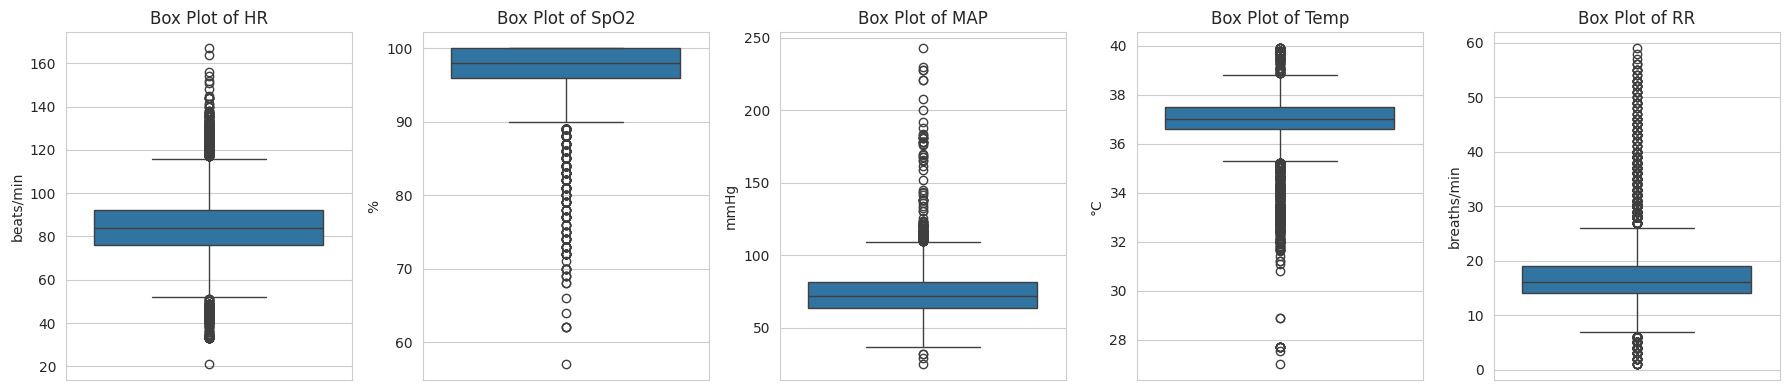

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, numeric_columns):
    sns.boxplot(y=df[col].sample(min(50000, len(df)), random_state=0), ax=ax)
    ax.set_title(f"Box Plot of {col}"); ax.set_ylabel(UNITS[col])
plt.tight_layout(); plt.show()

### Are the IQR outliers errors or real events?

Compare the statistical outliers with the **clinically abnormal** ranges (HR < 50 or > 100, SpO₂ < 92, MAP < 60 or > 120, Temp < 35 or > 38, RR < 8 or > 20).

In [11]:
ABNORMAL = {"HR": (50, 100), "SpO2": (92, np.inf), "MAP": (60, 120), "Temp": (35, 38), "RR": (8, 20)}

rows = []
for v in VITALS:
    lo, hi = ABNORMAL[v]
    clin_abn = (df[v] < lo) | (df[v] > hi)
    both = outlier_mask[v] & clin_abn
    rows.append({"Vital": v, "IQR outliers": int(outlier_mask[v].sum()), "Clinically abnormal": int(clin_abn.sum()),
                 "IQR outliers that are clinically abnormal %": round(both.sum() / max(outlier_mask[v].sum(), 1) * 100, 1)})
overlap_tbl = pd.DataFrame(rows).set_index("Vital")
display(overlap_tbl)
iqr_total = int(outlier_mask.to_numpy().sum())
both_total = int(sum(((outlier_mask[v]) & ((df[v] < ABNORMAL[v][0]) | (df[v] > ABNORMAL[v][1]))).sum() for v in VITALS))
overlap_pct = both_total / max(iqr_total, 1) * 100
print(f"Overall: {overlap_pct:.1f}% of IQR outliers are also clinically abnormal.")
print("Reading: a high percentage means the IQR 'outliers' are mostly genuine physiological events, not errors.")

,IQR outliers,Clinically abnormal,IQR outliers that are clinically abnormal %
Vital,,,
HR,591,1561,98.8
SpO2,318,550,100.0
MAP,141,1521,44.7
Temp,627,1129,93.3
RR,928,2139,100.0


Overall: 95.1% of IQR outliers are also clinically abnormal.
Reading: a high percentage means the IQR 'outliers' are mostly genuine physiological events, not errors.


### Remove IQR outliers?

**Decision: not removed by default.** Extreme blood pressure, heart rate and especially SpO₂ values are exactly the events this project wants to find. SpO₂ sits close to 100 % almost all the time, so its IQR is tiny and *every* real desaturation is flagged as an "outlier". Only the physiologically impossible readings were removed (section 6).

The switch below lets you see the effect of removing them anyway.

In [12]:
REMOVE_IQR_OUTLIERS = False          # set True only to demonstrate the effect

would_remove = outlier_mask.any(axis=1)
print(f"Rows that IQR removal would delete: {would_remove.sum():,} ({would_remove.mean():.1%} of the data)")

if REMOVE_IQR_OUTLIERS:
    df_clean = df[~would_remove].copy()
    print("Before outlier removal:", df.shape)
    print("After outlier removal:", df_clean.shape)
    df = df_clean.copy()
else:
    print("Kept all rows (clinically meaningful extremes preserved).")

Rows that IQR removal would delete: 1,960 (18.2% of the data)
Kept all rows (clinically meaningful extremes preserved).


## 9. Final Data-Quality Check

In [13]:
print("Final shape:", df.shape)
print("Missing values:")
display(df.isnull().sum())
print("Duplicate (caseid, time) records:", df.duplicated(["caseid", "time_s"]).sum())
print("Impossible values left:", int(sum(((df[v] < lo) | (df[v] > hi)).sum() for v, (lo, hi) in PLAUSIBLE.items())))

Final shape: (10759, 12)
Missing values:


,0
caseid,0
time_s,0
HR,0
SpO2,0
MAP,0
Temp,0
RR,0
gender,0
age,0
unit_type,0


Duplicate (caseid, time) records: 0
Impossible values left: 0


## 10. Statistical Analysis

Besides the usual summary, the table shows **skewness** (asymmetry) and the **percentage of time each vital spent outside its normal clinical range**.

In [14]:
for v in VITALS:
    lo, hi = ABNORMAL[v]
    df[f"{v}_status"] = np.select([df[v] < lo, df[v] > hi], ["Low", "High"], "Normal")

display(df[numeric_columns].describe().T)

stats = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Std Dev": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max(),
    "Skewness": df[numeric_columns].skew(),
    "% time abnormal": [(df[f"{v}_status"] != "Normal").mean() * 100 for v in VITALS],
}).round(2)
display(stats)

,count,mean,std,min,25%,50%,75%,max
HR,10759.0,84.390557,15.048175,21.0,76.0,84.0,92.0,167.0
SpO2,10759.0,97.226601,3.720450,57.0,96.0,98.0,100.0,100.0
MAP,10759.0,73.755182,14.454508,25.0,64.0,72.0,82.0,243.0
Temp,10759.0,36.919915,1.070560,27.0,36.6,37.0,37.5,39.9
RR,10759.0,16.983177,6.311785,1.0,14.0,16.0,19.0,59.0


,Mean,Median,Std Dev,Minimum,Maximum,Skewness,% time abnormal
HR,84.39,84.0,15.05,21.0,167.0,0.08,14.51
SpO2,97.23,98.0,3.72,57.0,100.0,-3.04,5.11
MAP,73.76,72.0,14.45,25.0,243.0,1.93,14.14
Temp,36.92,37.0,1.07,27.0,39.9,-2.32,10.49
RR,16.98,16.0,6.31,1.0,59.0,1.82,19.88


## 11. Univariate Analysis – Histograms

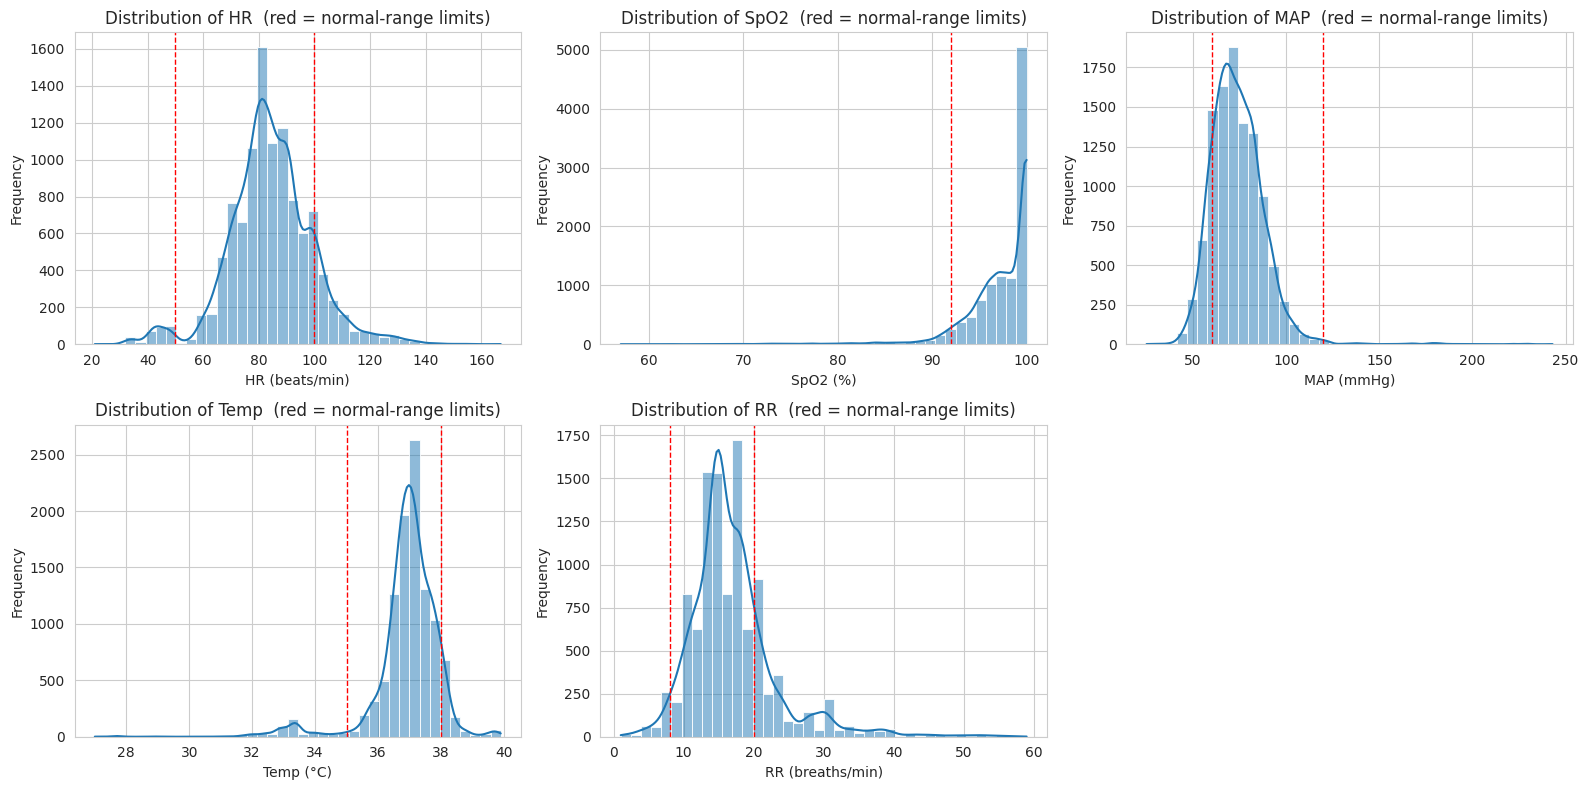

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
smp = df.sample(min(100000, len(df)), random_state=0)
for ax, col in zip(axes.ravel(), numeric_columns):
    sns.histplot(smp[col], kde=True, ax=ax, bins=40)
    for lim in ABNORMAL[col]:
        if np.isfinite(lim): ax.axvline(lim, color="red", ls="--", lw=1)
    ax.set_title(f"Distribution of {col}  (red = normal-range limits)")
    ax.set_xlabel(f"{col} ({UNITS[col]})"); ax.set_ylabel("Frequency")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## 12. Univariate Analysis – Count Plots

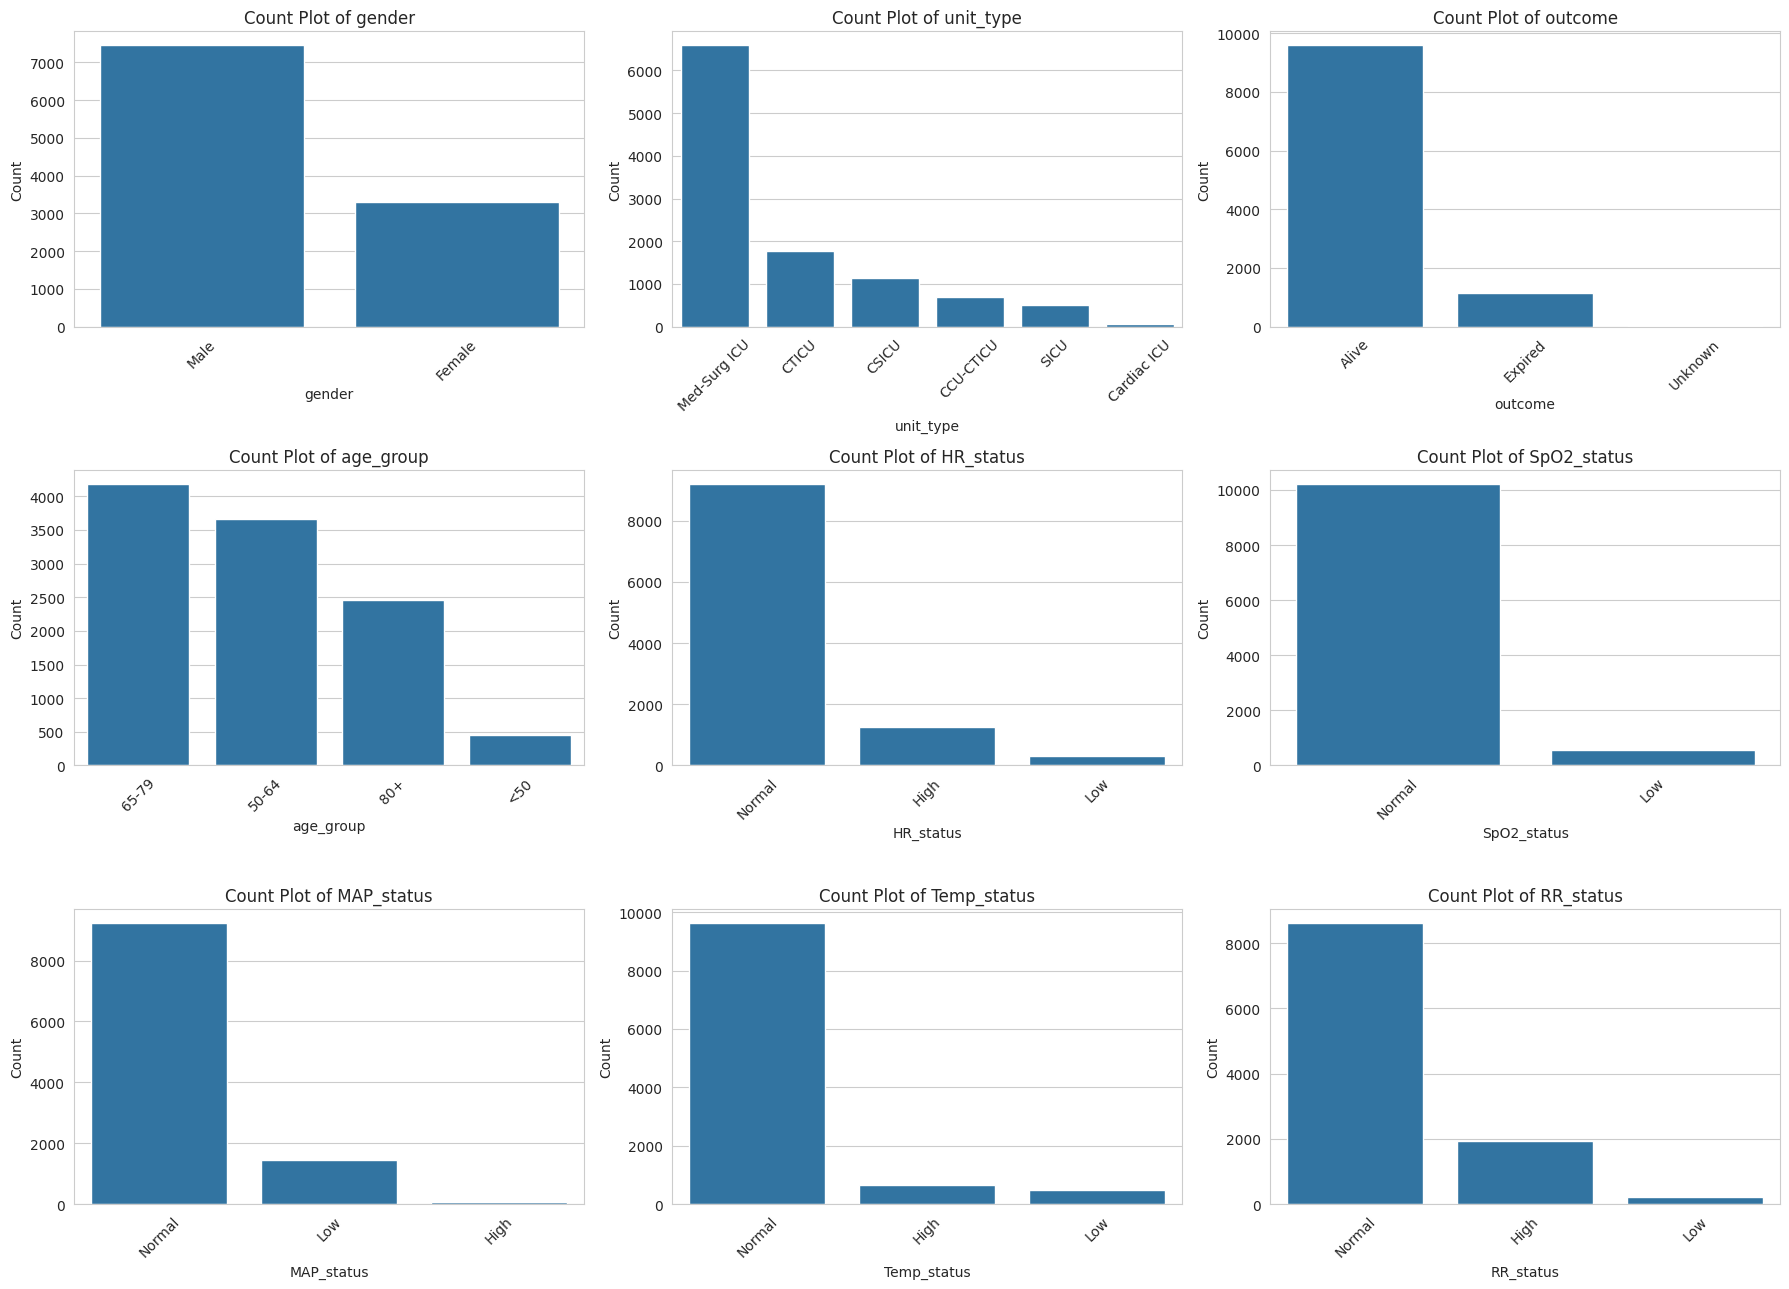

In [16]:
count_cols = categorical_columns + [f"{v}_status" for v in VITALS]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, col in zip(axes.ravel(), count_cols):
    if df[col].nunique() <= 20:
        sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
        ax.set_title(f"Count Plot of {col}"); ax.set_xlabel(col); ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=45)
for ax in axes.ravel()[len(count_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 13. Bivariate Analysis – Scatter Plots

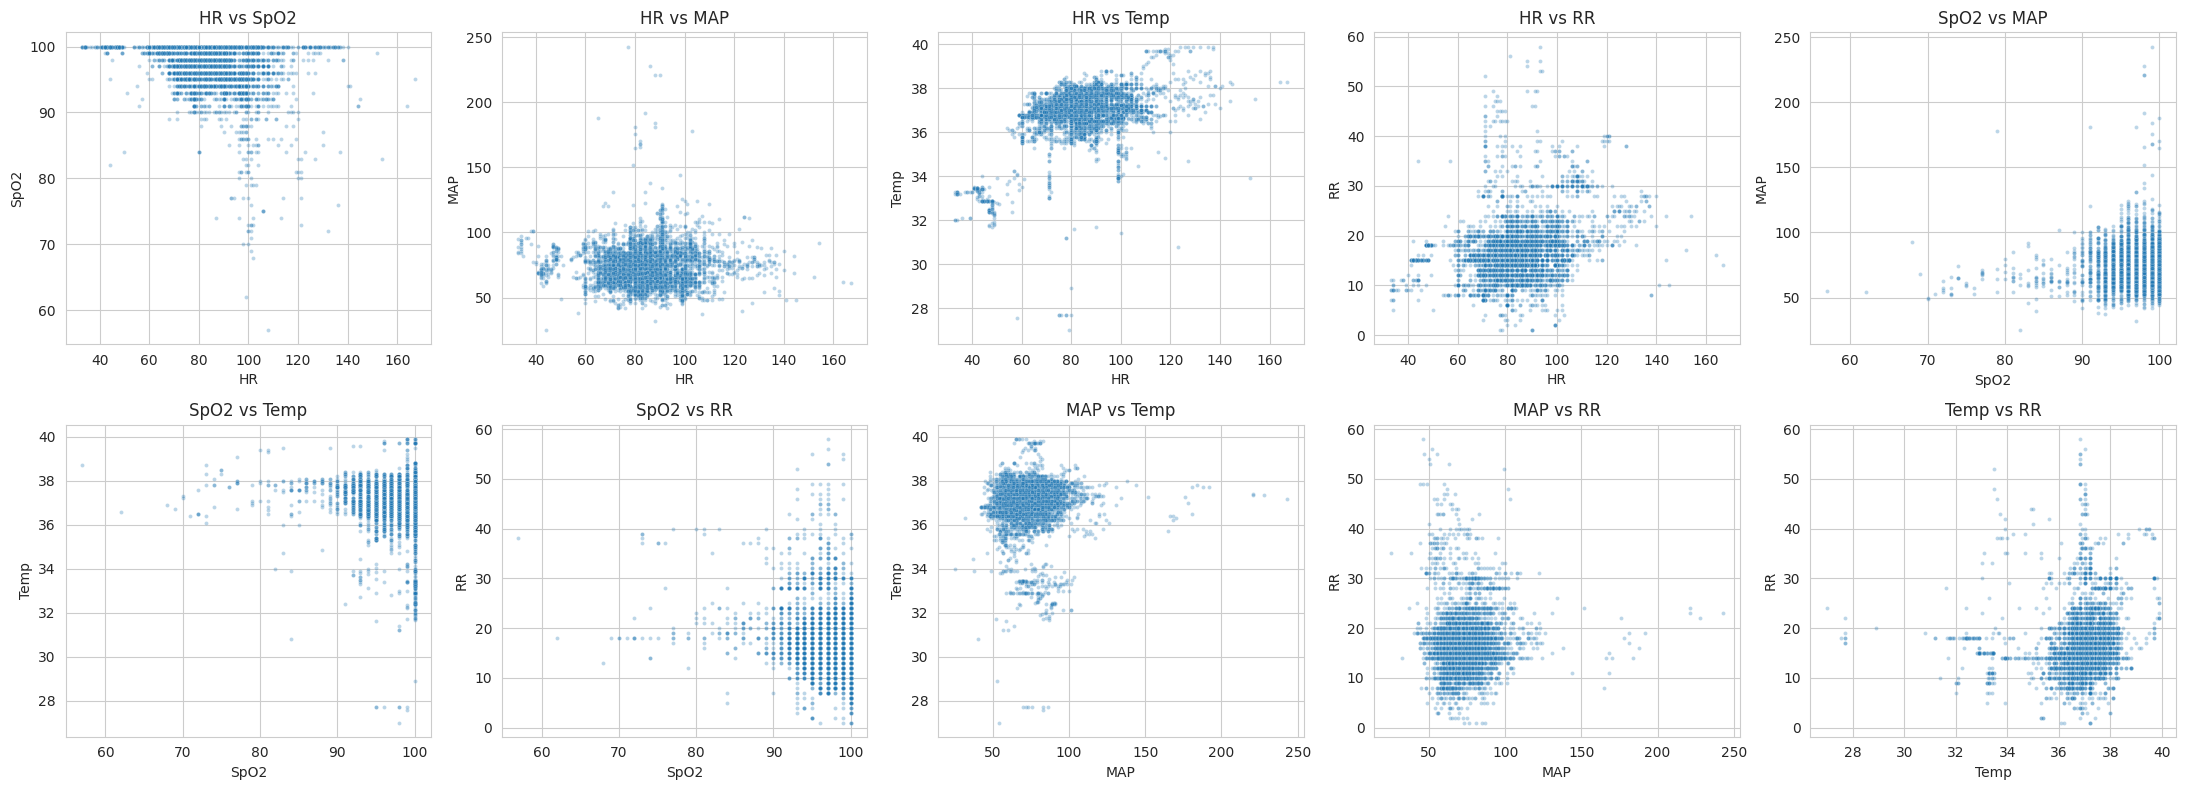

In [17]:
smp = df.sample(min(5000, len(df)), random_state=1)
pairs_list = [(VITALS[i], VITALS[j]) for i in range(5) for j in range(i + 1, 5)]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, (x, y) in zip(axes.ravel(), pairs_list):
    sns.scatterplot(data=smp, x=x, y=y, s=8, alpha=0.3, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout(); plt.show()

## 14. Bivariate Analysis – Categorical vs Numerical

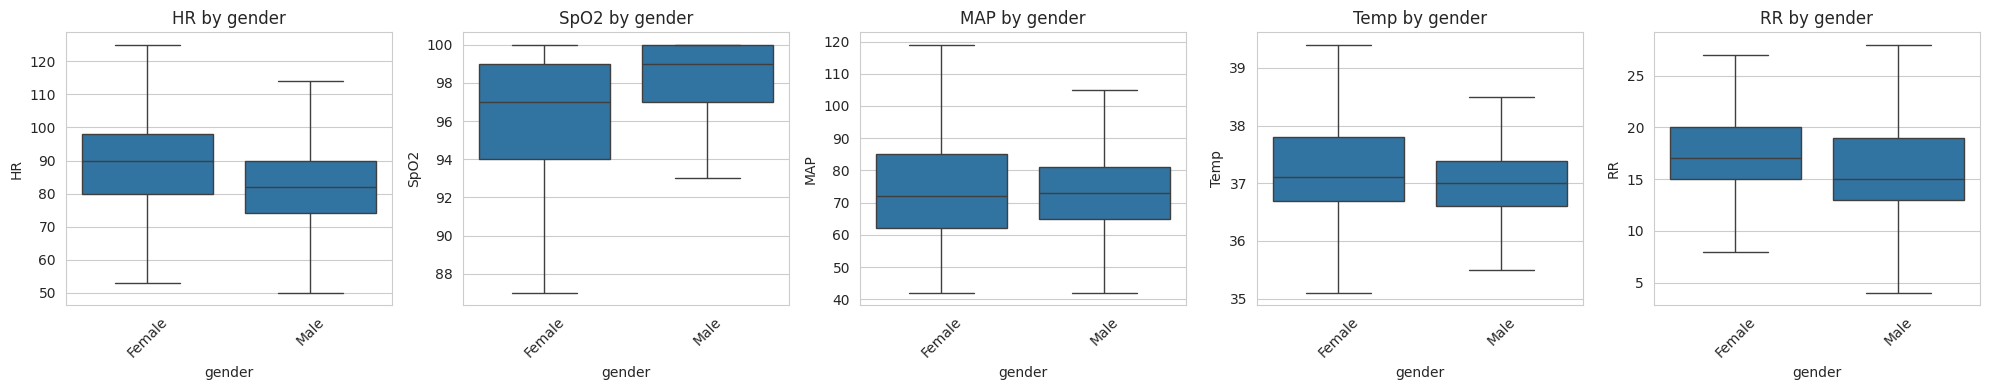

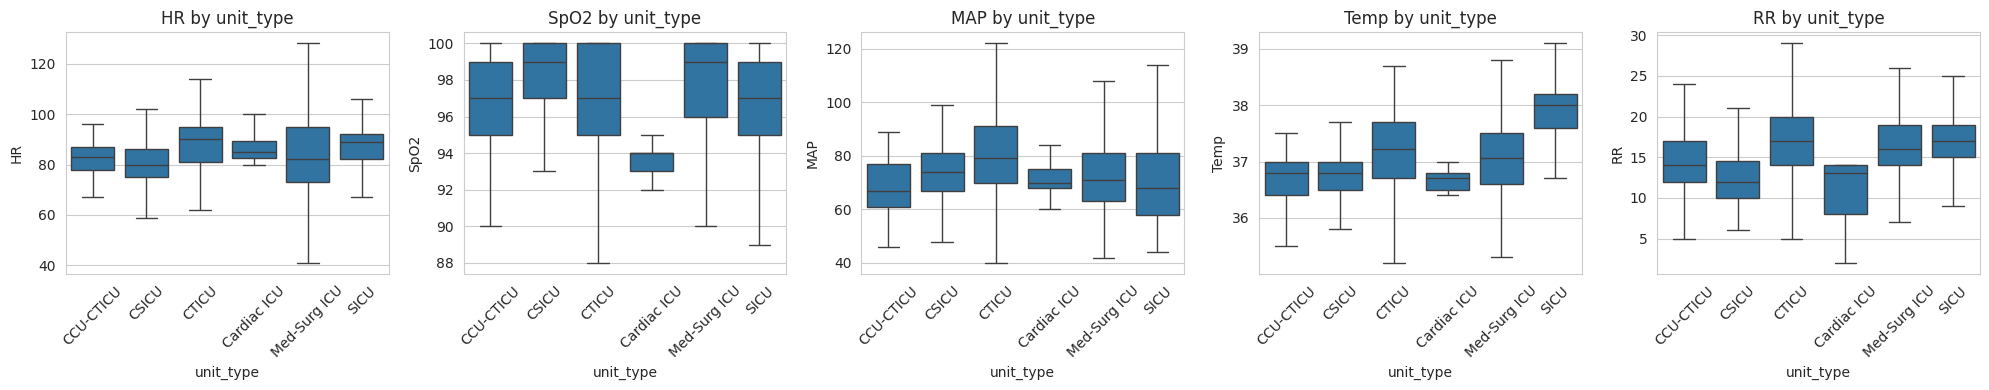

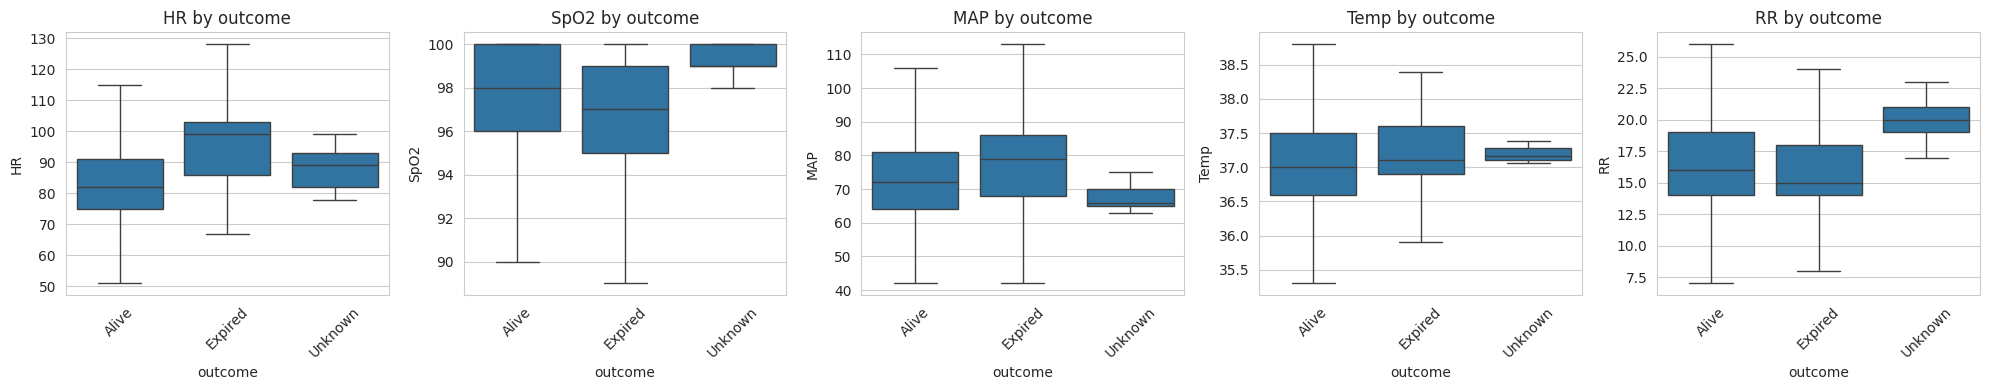

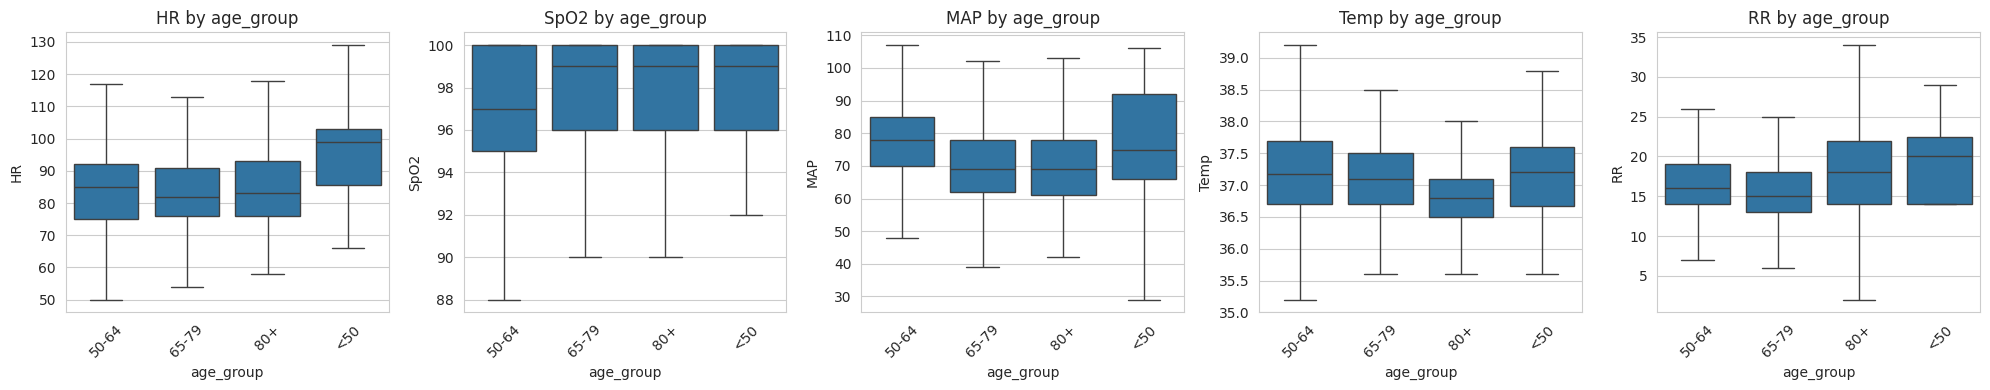

In [18]:
smp = df.sample(min(60000, len(df)), random_state=2)   # row-level boxplots
for cat in categorical_columns:
    if df[cat].nunique() <= 15:
        fig, axes = plt.subplots(1, 5, figsize=(20, 4))
        order = sorted(df[cat].unique())
        for ax, num in zip(axes, numeric_columns):
            sns.boxplot(data=smp, x=cat, y=num, order=order, showfliers=False, ax=ax)
            ax.set_title(f"{num} by {cat}"); ax.tick_params(axis="x", rotation=45)
        plt.tight_layout(); plt.show()


### Do patients who died differ from survivors?

Each patient contributes thousands of correlated rows, so rows must not be compared directly. Instead each patient is reduced to **one median per vital**, and the two outcome groups are compared with a Mann-Whitney U test (a rank test that does not assume a normal distribution).


In [19]:
from scipy.stats import mannwhitneyu

mw_table = pd.DataFrame()
if "outcome" in df.columns:
    per_patient = df.groupby("caseid")[VITALS].median().join(df.groupby("caseid")["outcome"].first())
    alive, dead = per_patient[per_patient.outcome == "Alive"], per_patient[per_patient.outcome == "Expired"]
    if len(alive) >= 3 and len(dead) >= 3:
        rows = []
        for v in VITALS:
            rows.append({"Vital": v, "Alive: median": alive[v].median(), "Expired: median": dead[v].median(),
                         "p-value": mannwhitneyu(alive[v], dead[v]).pvalue})
        mw_table = pd.DataFrame(rows).set_index("Vital").round(3)
        print(f"Patients: {len(alive)} alive, {len(dead)} expired (small groups: interpret with care)")
        display(mw_table)
    else:
        print(f"Too few patients in one outcome group (alive={len(alive)}, expired={len(dead)}) for a test; increase N_STAYS.")

Patients: 50 alive, 6 expired (small groups: interpret with care)


,Alive: median,Expired: median,p-value
Vital,,,
HR,83.5,100.00,0.008
SpO2,98.5,96.00,0.261
MAP,72.0,79.50,0.801
Temp,37.1,37.15,0.801
RR,16.0,15.00,0.661


## 15. Correlation Analysis and Heatmap

Three views are shown:
* **Pearson** (linear) and **Spearman** (rank) correlation over all rows;
* **Within-patient** correlation, after subtracting each patient's own average. This removes differences *between* patients (a patient with high blood pressure all along) and shows how the vitals move *together over time* in the same patient.

,HR,SpO2,MAP,Temp,RR
HR,1.000000,-0.312889,0.008772,0.477167,0.299580
SpO2,-0.312889,1.000000,0.068196,-0.185585,-0.268899
MAP,0.008772,0.068196,1.000000,0.025282,-0.007995
Temp,0.477167,-0.185585,0.025282,1.000000,0.147317
RR,0.299580,-0.268899,-0.007995,0.147317,1.000000


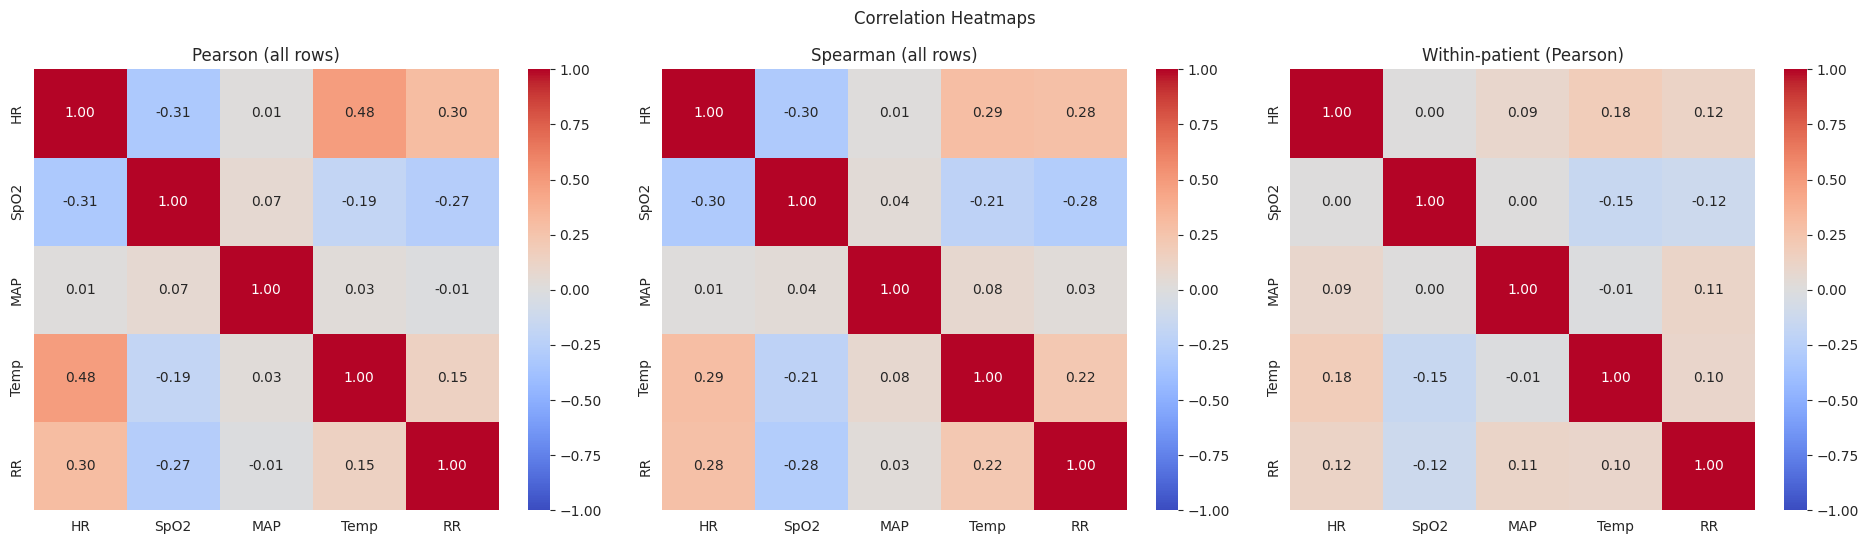

In [20]:
corr = df[numeric_columns].corr()
corr_s = df[numeric_columns].corr(method="spearman")
within = df[numeric_columns] - df.groupby("caseid")[numeric_columns].transform("mean")
corr_w = within.corr()
display(corr)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, c, t in zip(axes, [corr, corr_s, corr_w], ["Pearson (all rows)", "Spearman (all rows)", "Within-patient (Pearson)"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(t)
plt.suptitle("Correlation Heatmaps"); plt.tight_layout(); plt.show()

## 16. Strongest Correlations

In [21]:
def top_pairs(c, n=10):
    return (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
             .sort_values(key=lambda x: x.abs(), ascending=False).head(n))

pairs = top_pairs(corr)
display(pd.DataFrame({"Pearson": pairs, "Spearman": [corr_s.loc[a, b] for a, b in pairs.index],
                      "Within-patient": [corr_w.loc[a, b] for a, b in pairs.index]}).round(3))

Pearson  Spearman  Within-patient
HR   Temp    0.477     0.294           0.185
     SpO2   -0.313    -0.304           0.002
     RR      0.300     0.276           0.121
SpO2 RR     -0.269    -0.281          -0.119
     Temp   -0.186    -0.214          -0.148
Temp RR      0.147     0.224           0.100
SpO2 MAP     0.068     0.037           0.003
MAP  Temp    0.025     0.076          -0.009
HR   MAP     0.009     0.014           0.089
MAP  RR     -0.008     0.028           0.115

## 17. Pair Plot (multivariate view)

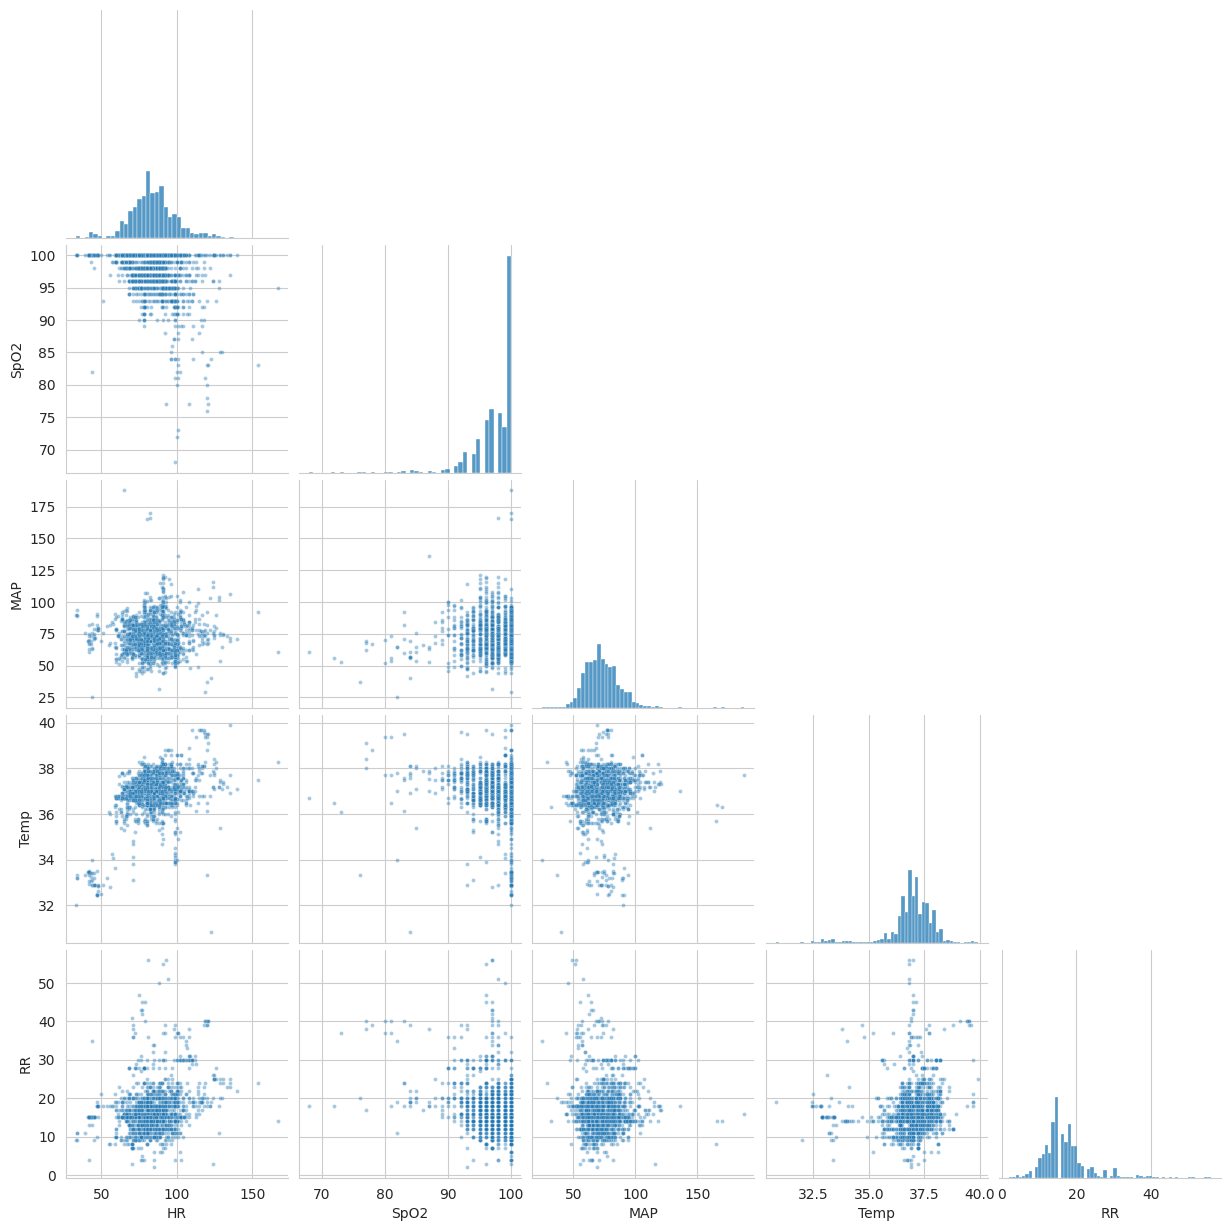

In [22]:
pair_cols = numeric_columns
if len(pair_cols) >= 2:
    sample = df.sample(min(1500, len(df)), random_state=3)
    sns.pairplot(sample[pair_cols].dropna(), corner=True, plot_kws={"s": 8, "alpha": 0.4})
    plt.show()
else:
    print("Not enough numerical columns for a pair plot.")

## 17b. Additional Analysis – Time-Series Patterns (specific to monitoring data)

Monitoring data are *ordered in time*, which the standard EDA steps ignore. Three extra views: one patient's recording, the typical trend over the first day in ICU, and how often each vital is abnormal for different patient groups.

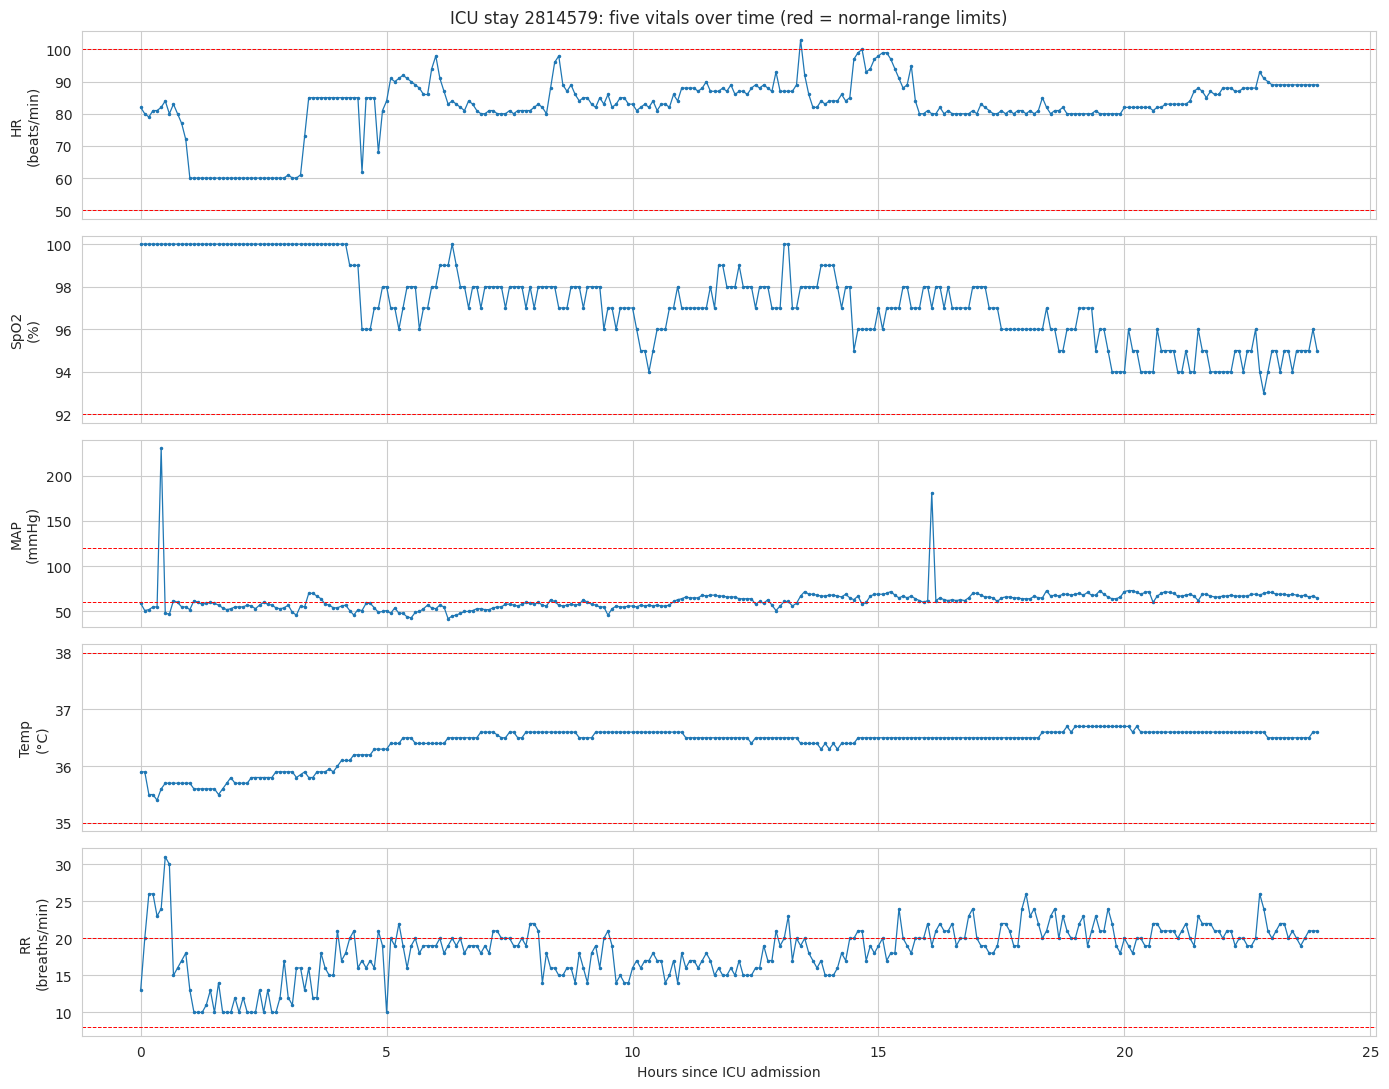

In [23]:
# (a) One complete recording, gaps preserved
best = df.groupby("caseid").size().idxmax()
d = df_ts[df_ts.caseid == best]
fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for ax, v in zip(axes, VITALS):
    ax.plot(d.time_s / 3600, d[v], lw=0.9, marker=".", ms=3)
    for lim in ABNORMAL[v]:
        if np.isfinite(lim): ax.axhline(lim, ls="--", lw=0.7, color="red")
    ax.set_ylabel(f"{v}\n({UNITS[v]})")
axes[0].set_title(f"ICU stay {best}: five vitals over time (red = normal-range limits)")
axes[-1].set_xlabel("Hours since ICU admission")
plt.tight_layout(); plt.show()

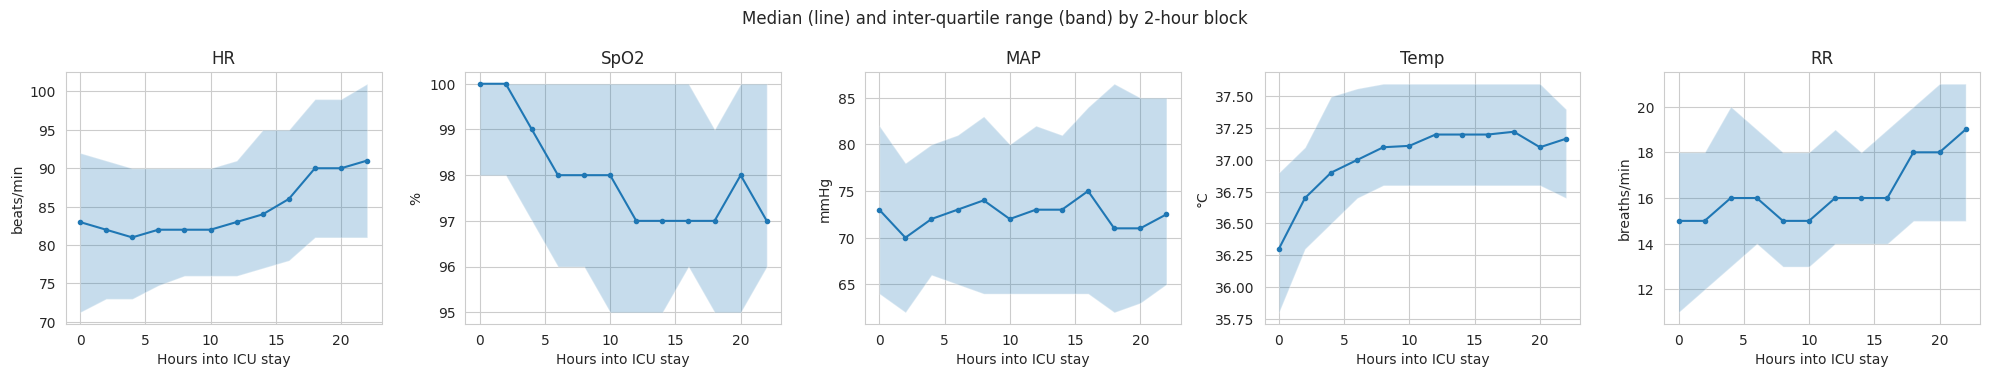

In [24]:
# (b) Typical trend: median and inter-quartile band per 2-hour block
df["elapsed_h"] = df["time_s"] / 3600
df["block"] = (df["elapsed_h"] // 2 * 2).astype(int)
trend = df[df.block <= 22].groupby("block")[VITALS].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, v in zip(axes, VITALS):
    ax.plot(trend.index, trend[(v, "median")], marker="o", ms=3)
    ax.fill_between(trend.index, trend[(v, "<lambda_0>")], trend[(v, "<lambda_1>")], alpha=0.25)
    ax.set_title(v); ax.set_xlabel("Hours into ICU stay"); ax.set_ylabel(UNITS[v])
plt.suptitle("Median (line) and inter-quartile range (band) by 2-hour block"); plt.tight_layout(); plt.show()

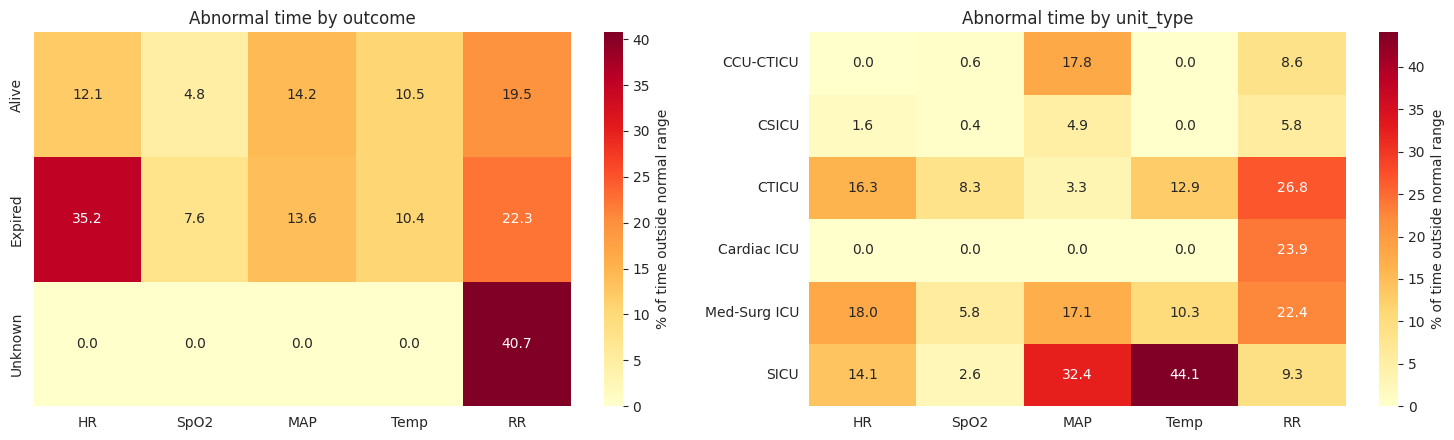

In [25]:
# (c) Share of time abnormal, by patient group
group_cols = [c for c in ["outcome", "unit_type"] if c in df.columns]
fig, axes = plt.subplots(1, len(group_cols), figsize=(7.5 * len(group_cols), 4.5))
axes = np.atleast_1d(axes)
for ax, g in zip(axes, group_cols):
    ab = pd.DataFrame({v: (df[f"{v}_status"] != "Normal") for v in VITALS}).groupby(df[g]).mean() * 100
    sns.heatmap(ab, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of time outside normal range"}, ax=ax)
    ax.set_title(f"Abnormal time by {g}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 18. Key Findings

The cell below fills the findings **from your own results**, so the numbers always match the outputs above. Copy them into your report and add your own interpretation.

In [26]:
n_raw, c_raw = df_raw.shape
miss_txt = ", ".join(f"{v} {missing.loc[v, 'Missing Percentage']:.1f}%" for v in VITALS)
top_out = outlier_count.sort_values(ascending=False)
skew = stats["Skewness"]; most_skew = skew.abs().idxmax()
a, b = pairs.index[0]; strongest = pairs.iloc[0]
(a2, b2) = top_pairs(corr_w, 1).index[0]; strongest_w = top_pairs(corr_w, 1).iloc[0]
abn = stats["% time abnormal"]
t_first = df.loc[df.block <= 2, "Temp"].median(); t_last = df.loc[df.block >= 16, "Temp"].median()
sig = list(mw_table.index[mw_table["p-value"] < 0.05]) if len(mw_table) else []
out_txt = (f"vitals that differ significantly between survivors and non-survivors (p<0.05): {', '.join(sig)}" if sig
           else "no vital differs significantly between survivors and non-survivors (small groups, so this is not conclusive)") if len(mw_table) else "outcome comparison not possible (too few patients in one group)"

findings = f"""
1. Dataset size: {n_raw:,} rows and {c_raw} columns as loaded ({df_raw.caseid.nunique()} ICU stays, first {HOURS} h each); {len(df):,} rows x {df.shape[1]} columns after cleaning ({len(df)/n_raw:.0%} of the original rows).
2. Missing values (before treatment): {miss_txt}.
3. Duplicate records: {dup_key} true duplicates (same stay and time); {inconsistent[['Below','Above']].sum().sum()} physiologically impossible readings were set to missing.
4. Outliers (IQR) were found most in: {top_out.index[0]} ({top_out.iloc[0]:,} rows, {top_out.iloc[0]/len(df):.1%}); fewest in {top_out.index[-1]}.
   {overlap_pct:.0f}% of IQR outliers are also clinically abnormal ({"so most are real physiological events" if overlap_pct >= 50 else "so many are only statistical extremes"}); all were kept because impossible values had already been removed.
5. Important distribution/pattern: {most_skew} is the most skewed vital (skewness {skew[most_skew]:+.2f}); the vital that spends most time outside its normal range is {abn.idxmax()} ({abn.max():.1f}% of the time).
6. Important relationship: the within-patient correlation is strongest for {a2}-{b2} (r = {strongest_w:+.2f}).
7. Strongest correlation over all rows: {a}-{b} (Pearson r = {strongest:+.2f}).
8. Important comparison/trend: median body temperature is {t_first:.1f} °C in hours 0-4 and {t_last:.1f} °C in hours 16-24 of the ICU stay; {out_txt}.
"""
print(findings)


1. Dataset size: 16,592 rows and 12 columns as loaded (60 ICU stays, first 24 h each); 10,759 rows x 19 columns after cleaning (65% of the original rows).
2. Missing values (before treatment): HR 2.6%, SpO2 6.3%, MAP 18.1%, Temp 22.2%, RR 6.6%.
3. Duplicate records: 0 true duplicates (same stay and time); 1114 physiologically impossible readings were set to missing.
4. Outliers (IQR) were found most in: RR (928 rows, 8.6%); fewest in MAP.
   95% of IQR outliers are also clinically abnormal (so most are real physiological events); all were kept because impossible values had already been removed.
5. Important distribution/pattern: SpO2 is the most skewed vital (skewness -3.04); the vital that spends most time outside its normal range is RR (19.9% of the time).
6. Important relationship: the within-patient correlation is strongest for HR-Temp (r = +0.18).
7. Strongest correlation over all rows: HR-Temp (Pearson r = +0.48).
8. Important comparison/trend: median body temperature is 36.5 °C

## 19. Conclusion

The cell below drafts the conclusion from your results. Edit it in your own words before submitting.

In [27]:
print(f"""
The eICU Demo sample ({df_raw.caseid.nunique()} ICU stays, {n_raw:,} five-minute observations of heart rate, SpO2, invasive mean blood pressure, temperature and respiratory rate)
needed domain-aware cleaning rather than the generic steps. Missing values were treated as sensor- or recording-related gaps (not random), so short gaps were
bridged within each patient instead of being filled with the median, and {len(df)/len(df_ts):.0%} of the time slots had all five vitals. Physiologically impossible values were treated as sensor artifacts.
Because eICU stores 5-minute medians, very short spikes are already smoothed out, so artifacts are less frequent than in second-by-second operating-theatre data.

IQR flagged outliers in {int((outlier_count > 0).sum())} of 5 vitals; {overlap_pct:.0f}% of them also fall outside the clinical normal range ({"mostly real physiological events" if overlap_pct >= 50 else "so many are only statistical extremes"}).
They were kept: removing them would have deleted {would_remove.mean():.1%} of the data, including the situations a monitoring study is meant to find.

{most_skew} was the most skewed vital and {abn.idxmax()} spent the most time outside its normal range ({abn.max():.1f}%). The strongest overall correlation was {a}-{b} (r = {strongest:+.2f});
within the same patient, {a2}-{b2} moved together most (r = {strongest_w:+.2f}). Such multi-vital agreement is useful for telling genuine physiological change
(several vitals move together) from a single-sensor artifact, which is the next step of this project.
""")


The eICU Demo sample (60 ICU stays, 16,592 five-minute observations of heart rate, SpO2, invasive mean blood pressure, temperature and respiratory rate)
needed domain-aware cleaning rather than the generic steps. Missing values were treated as sensor- or recording-related gaps (not random), so short gaps were
bridged within each patient instead of being filled with the median, and 65% of the time slots had all five vitals. Physiologically impossible values were treated as sensor artifacts.
Because eICU stores 5-minute medians, very short spikes are already smoothed out, so artifacts are less frequent than in second-by-second operating-theatre data.

IQR flagged outliers in 5 of 5 vitals; 95% of them also fall outside the clinical normal range (mostly real physiological events).
They were kept: removing them would have deleted 18.2% of the data, including the situations a monitoring study is meant to find.

SpO2 was the most skewed vital and RR spent the most time outside its normal ra

# Assignment 2 – Poster Presentation and Reproducible Project

**Student:** Sangeetha  
**Project:** Abnormal Patterns in Continuous Patient Monitoring

This section adds a reproducible, rule-based abnormal-pattern summary to the Assignment 1 EDA. It is an educational analysis of the eICU Demo sample, not a clinical decision-support system. Thresholds are simplified and must not be interpreted as medical advice.

## Rule-based monitoring flags
The next cell creates low/high flags for each vital sign using the same illustrative ranges used in the EDA. It reports both observation-level flags and the proportion of patients with at least one flagged observation. The rule-based flags are not a trained machine-learning model and do not diagnose a condition.

## Exportable results for the poster
The cells write summary tables to `results/` when run in the project folder. Copy plots you want to present into the same folder. Since data are downloaded from PhysioNet, the raw data are not included in this repository.


In [ ]:
# Assignment 2: transparent rule-based abnormal-pattern flags
# Uses the ABNORMAL ranges defined earlier in the notebook.
import os
os.makedirs("../results", exist_ok=True)

flag_summary_rows = []
for vital in VITALS:
    lo, hi = ABNORMAL[vital]
    if np.isfinite(hi):
        flagged = (df[vital] < lo) | (df[vital] > hi)
        rule = f"< {lo} or > {hi} {UNITS[vital]}"
    else:
        flagged = df[vital] < lo
        rule = f"< {lo} {UNITS[vital]}"
    df[f"{vital}_flag"] = flagged.fillna(False)
    flag_summary_rows.append({
        "Vital": vital,
        "Illustrative flag rule": rule,
        "Flagged observations": int(flagged.sum()),
        "Flagged observation percentage": round(float(flagged.mean() * 100), 2),
        "Patients with >=1 flag": int(df.loc[flagged, "caseid"].nunique())
    })

flag_summary = pd.DataFrame(flag_summary_rows)
display(flag_summary)
flag_summary.to_csv("../results/abnormal_flag_summary.csv", index=False)

# Patient-level summaries avoid treating every 5-minute observation as an independent patient.
patient_summary = df.groupby("caseid").agg(
    observations=("time_s", "size"),
    **{f"{v}_median": (v, "median") for v in VITALS},
    **{f"{v}_missing_pct": (v, lambda s: round(s.isna().mean()*100, 2)) for v in VITALS}
).reset_index()
patient_summary.to_csv("../results/patient_level_summary.csv", index=False)
print("Saved results/abnormal_flag_summary.csv and results/patient_level_summary.csv")


## Poster reporting checklist
Before submission, run the notebook from top to bottom and use the generated output values rather than estimated numbers. Include:
- dataset source and sample size;
- missingness and cleaning decisions;
- at least three readable, captioned figures;
- one correlation heatmap;
- key findings supported by actual output;
- limitations: demo dataset, sample of ICU stays, rule-based thresholds, and no clinical validation.
